# Simulation: Source Spike with Propagation

Explain simulation please

## 📦 Imports

In [1]:
import mindmap as mm

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `eeg`: EEG template
- `fwd`: Forward solution
- `sc`: Structural connectome
- `parc`: Parcellation
- `cras`: Transformation (MRI -> RAS)
- `white`: Inner cortical surface
- `hmodel`: Head conductor model 
- `cst`: Connectome spectrum transform
- `ctx`: Cortical mask

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id (position in list SUBS)

In [2]:
############### Parameters #################
fconfig = "../../papers/simf/configuration.yml"
sub     = 0
############################################

# configuration
reader = mm.io.dataset_reader(fconfig)

# data
data = reader(sub, "eeg", "fwd", "sc", "parc", "cras", "white", "bem", "cst", "ctx")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg
- bem
- parc
- cst
- fwd
- white
- cras
- sc
- ctx
Missing objects:


## Simulation

#### ⚙️ **<font color=green>Generate simulation</font>**
🛠️ **<font color=violet>Source Spike</font>**:
- `duration`: duration of the simulation
- `width`: duration of the spike
- `location`: location of the source spike given by a brain region

🛠️ **<font color=violet>Spike Propagation</font>**:
- `conductance`: Propagation weight [0-1]
- `delay`: Propagation delay in [ms]

🛠️ **<font color=violet>Noise Generation</font>**:
- `target_snr`: Maximum EEG SNR in [dB] expcted
- `noise_ratio`: Ratio [0-1] between brain noise and EEG electrical noise.

In [3]:

########################### Parameters #############################
# Source Spike
duration  = 1000
width     = 100
location  = "random"

# Spike Propagation
conduction      = 0.25
conductance_std = 0  
delay           = 30
delay_std       = 0

# Noise Generation
target_snr  = 15
noise_ratio = 0.9
######################################################################

sim = mm.utils.Simulation(data["fwd"], data["sc"], info=data["eeg"].info, duration=duration, parcellation=data["parc"], cras=data["cras"])
sim.set_spike_attr(width=width, onset=500)
sim.set_prop_attr(conduction=conduction, delay=delay)
sim.set_noise_attr(snr=target_snr, noise_ratio=noise_ratio)
sim.run()

sim.summary()

SIMULATION SUMMARY
Simulation info
- Duration: 1.0 [s]
- Sampling rate: 250.0
Source Space info:
- Number of dipoles: 4961
- Noise type: pink
- Noise contribution: 0.9
EEG info:
- Number of electrodes: 203
- Target SNR: 15 [dB]
- Adjusted SNR: 15.082518310275132 [dB]
- Noise type: white
- Noise contribution: 0.09999999999999998
Spike info:
- Location: ctx-lh-inferiorparietal_2
- Onset: 500 [ms]
- Amplitude: 1e-09 [A]
- Duration: 100 [ms]
- Maximum: 0.532 [ms]
Propagation info:
- Conductance: 0.25
- Delay: 30 [ms]


#### 🌟 Visualize Simulation

🛠️ **<font color=violet>Simulation plots</font>**:
- `plot`: Plot type. Can be one of ["spike", "brain", "eeg", "noise"]

<font color=red>A good range for EEG electrodes is 10 to 200 uV</font>

Half rising phase:  0.544
Peak phase:  0.56


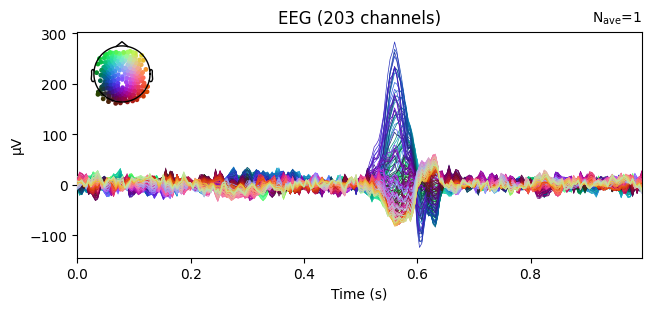

In [4]:
########################### Parameters #############################
# choose plot ("spike", "brain", "eeg", "noise")
plot = "eeg"
####################################################################

half_phase = mm.utils.eeg_rising_phase(sim.eeg, 0.5)
peak_phase = mm.utils.eeg_rising_phase(sim.eeg, 1)
print("Half rising phase: ", half_phase)
print("Peak phase: ", peak_phase)


if plot == "spike":
    _ = sim.plot_spike(noise=True)
elif plot == "brain":
    sim.plot_brain(noise=True).show()
elif plot == "eeg":
    sim.plot_eeg(noise=True)
elif plot == "noise":
    sim.plot_noise()
else:
    raise ValueError("Unknown plot type")


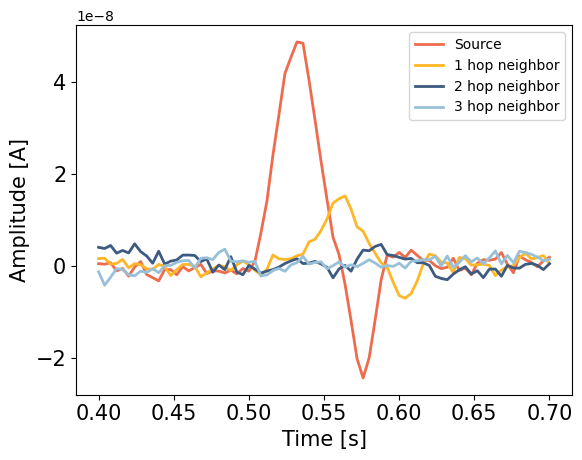

In [24]:
import matplotlib.pyplot as plt 

brain     = sim.get_activity(noise=True).copy()
brain     = brain.crop(0.4, 0.7)
neighbors = sim.visit

# plot 1 source, 1 1hop neighbor and 1 2hop neighbor
sources = brain.data[neighbors[0]]
hop1    = brain.data[neighbors[1]]
hop2    = brain.data[neighbors[2]]
hop3    = brain.data[neighbors[3]]

times = brain.times

plt.Figure()
plt.plot(times, sources[0], color="#EE6C4D", linewidth=2)
plt.plot(times, hop1[0], color="#FFB627", linewidth=2)
plt.plot(times, hop2[0], color="#3D5A80", linewidth=2)
plt.plot(times, hop3[0], color="#98C1D9", linewidth=2)

plt.xlabel("Time [s]", fontsize=15)
plt.ylabel("Amplitude [A]", fontsize=15)
plt.tick_params(labelsize=15)
plt.legend(["Source", "1 hop neighbor", "2 hop neighbor", "3 hop neighbor"])